In [48]:
import pandas as pd
import glob
import pycountry
import numpy as np

In [49]:
df_to_check=pd.read_csv("../newdata/named_cleaned_data.csv")
df_to_check.loc[df_to_check["Country Name"].str.contains("Germany"), "Mehrals1000Deutsche_boolean"] = True
df_to_check[df_to_check["Country Name"].str.contains("Germany")]["Mehrals1000Deutsche_boolean"]

137    True
Name: Mehrals1000Deutsche_boolean, dtype: bool

In [50]:
df_to_check=df_to_check.sort_values("Country Name").reset_index(drop=True)
df_to_check


,Country Name,Country Code,Land,BIP_rel_D,PurchasingPower_rel_D,Cost_BIP_Ratio,Bevoelkerungsdichte,Freedom_Score,PISA_Score,Sonnenstunde_pro_Tag,...,Healthcare,CostofLiving,LGBTQ,Mehrals5Morde_pro_100k_boolean,Mehrals1000Deutsche_boolean,Alkoholverbot_boolean,Kueste_boolean,Christian_boolean,Muslim_boolean,Jewish_boolean
0,Albania,ALB,Albanien,17.9,55.2,3.1,100.2,68.0,367.0,7.0,...,73.2,1023.0,62.3,False,False,False,True,True,True,False
1,Algeria,DZA,Algerien,10.1,41.6,4.1,19.4,31.0,NaN,8.9,...,72.9,467.0,3.7,False,False,False,True,False,True,False
2,Angola,AGO,Angola,3.8,32.9,8.7,29.5,28.0,NaN,6.4,...,50.0,817.0,48.6,False,False,False,True,True,True,False
3,Argentina,ARG,Argentinien,24.8,59.5,2.4,16.6,85.0,395.0,6.1,...,76.3,862.0,89.4,False,True,False,True,True,False,False
4,Armenia,ARM,Armenien,15.2,48.3,3.2,105.1,54.0,NaN,6.8,...,73.6,1088.0,43.2,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,Uzbekistan,UZB,Usbekistan,5.7,34.5,6.1,80.9,12.0,352.0,7.3,...,77.3,657.0,23.2,False,True,False,False,True,True,False
147,"Venezuela, RB",VEN,Venezuela,28.6,81.0,2.8,32.1,13.0,NaN,7.9,...,72.5,823.0,50.0,True,True,False,True,True,False,False
148,Viet Nam,VNM,Vietnam,8.5,37.3,4.4,320.2,20.0,468.0,5.8,...,77.3,616.0,52.3,False,False,False,True,True,False,False
149,Zambia,ZMB,Sambia,2.2,37.9,17.1,27.9,53.0,NaN,8.1,...,59.5,811.0,4.9,True,False,False,False,True,False,False


In [51]:
df_to_check=df_to_check.drop_duplicates(subset=['Country Name'], keep='first')

In [52]:
# Check what's in the problematic column
print(df_to_check['PISA_Score'].dtype)
print(df_to_check['PISA_Score'].unique()[:20])
print(f"Non-numeric values: {df_to_check['PISA_Score'][pd.to_numeric(df_to_check['PISA_Score'], errors='coerce').isna() & df_to_check['PISA_Score'].notna()].tolist()}")

float64
[367.  nan 395. 497. 486. 381. 397. 414. 337. 506. 435. 401. 404. 474.
 403. 491. 350. 360. 516. 495.]
Non-numeric values: []


In [53]:
# Make a clean copy
safe_countries_enough_data_red = df_to_check.copy()

# List of columns to convert to integers
int_cols = ['Freedom_Score', 'Zeitunterschied_D', 'PISA_Score', 'HoechsterPunkt_m',
            'NiedrigsterPunkt_m', 'EnglishSkill', 'LivingConditions', 'Healthcare',
            'CostofLiving', 'Rang_Kueche']

for col in int_cols:
    # Round first (handles decimals), then convert to Int64 (handles NaN)
    safe_countries_enough_data_red[col] = safe_countries_enough_data_red[col].round(0).astype('Int64')

safe_countries_enough_data_red

,Country Name,Country Code,Land,BIP_rel_D,PurchasingPower_rel_D,Cost_BIP_Ratio,Bevoelkerungsdichte,Freedom_Score,PISA_Score,Sonnenstunde_pro_Tag,...,Healthcare,CostofLiving,LGBTQ,Mehrals5Morde_pro_100k_boolean,Mehrals1000Deutsche_boolean,Alkoholverbot_boolean,Kueste_boolean,Christian_boolean,Muslim_boolean,Jewish_boolean
0,Albania,ALB,Albanien,17.9,55.2,3.1,100.2,68,367,7.0,...,73,1023,62.3,False,False,False,True,True,True,False
1,Algeria,DZA,Algerien,10.1,41.6,4.1,19.4,31,<NA>,8.9,...,73,467,3.7,False,False,False,True,False,True,False
2,Angola,AGO,Angola,3.8,32.9,8.7,29.5,28,<NA>,6.4,...,50,817,48.6,False,False,False,True,True,True,False
3,Argentina,ARG,Argentinien,24.8,59.5,2.4,16.6,85,395,6.1,...,76,862,89.4,False,True,False,True,True,False,False
4,Armenia,ARM,Armenien,15.2,48.3,3.2,105.1,54,<NA>,6.8,...,74,1088,43.2,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,Uzbekistan,UZB,Usbekistan,5.7,34.5,6.1,80.9,12,352,7.3,...,77,657,23.2,False,True,False,False,True,True,False
147,"Venezuela, RB",VEN,Venezuela,28.6,81.0,2.8,32.1,13,<NA>,7.9,...,72,823,50.0,True,True,False,True,True,False,False
148,Viet Nam,VNM,Vietnam,8.5,37.3,4.4,320.2,20,468,5.8,...,77,616,52.3,False,False,False,True,True,False,False
149,Zambia,ZMB,Sambia,2.2,37.9,17.1,27.9,53,<NA>,8.1,...,60,811,4.9,True,False,False,False,True,False,False


In [54]:
for col in safe_countries_enough_data_red.columns:
    print(col, safe_countries_enough_data_red[col].describe())
    print("--------------------")

Country Name count         150
unique        150
top       Albania
freq            1
Name: Country Name, dtype: object
--------------------
Country Code count     150
unique    150
top       ALB
freq        1
Name: Country Code, dtype: object
--------------------
Land count          150
unique         150
top       Albanien
freq             1
Name: Land, dtype: object
--------------------
BIP_rel_D count    150.000000
mean      34.520000
std       45.240479
min        0.300000
25%        4.800000
50%       14.450000
75%       46.375000
max      246.400000
Name: BIP_rel_D, dtype: float64
--------------------
PurchasingPower_rel_D count    149.000000
mean      60.658389
std       25.665299
min       16.200000
25%       42.400000
50%       53.400000
75%       73.800000
max      143.200000
Name: PurchasingPower_rel_D, dtype: float64
--------------------
Cost_BIP_Ratio count    149.000000
mean       7.655705
std       10.643856
min        0.500000
25%        1.500000
50%        3.400000
75%

In [55]:
safe_countries_enough_data_red.columns

Index(['Country Name', 'Country Code', 'Land', 'BIP_rel_D',
       'PurchasingPower_rel_D', 'Cost_BIP_Ratio', 'Bevoelkerungsdichte',
       'Freedom_Score', 'PISA_Score', 'Sonnenstunde_pro_Tag',
       'Zeitunterschied_D', 'Rang_Kueche', 'HoechsterPunkt_m',
       'NiedrigsterPunkt_m', 'EnglishSkill', 'BuerokratieScore',
       'MaxTemperatur', 'MinTemperatur', 'LivingConditions', 'Healthcare',
       'CostofLiving', 'LGBTQ', 'Mehrals5Morde_pro_100k_boolean',
       'Mehrals1000Deutsche_boolean', 'Alkoholverbot_boolean',
       'Kueste_boolean', 'Christian_boolean', 'Muslim_boolean',
       'Jewish_boolean'],
      dtype='object')

In [56]:
# here we create a dictionary for all indicators and all countries in the dataset
#which should be sorted first by countries, then by indicators

countries_dict={}
percentile_upper=90
percentile_lower=10
#so we go by each metric
for col in safe_countries_enough_data_red.columns[3:]:
    #if the metric is boolean
    if "boolean" in col:
        for iso3 in safe_countries_enough_data_red["Country Code"].tolist():
            print(iso3)
            #and the number of countries is more than one
            if (len(safe_countries_enough_data_red[safe_countries_enough_data_red["Country Code"]==iso3])>0):
                #we set the new inner dictionary accordingly, where both
                #the displayValue is the same as the binValue
                new_var={"id": col,
                "displayValue": bool(safe_countries_enough_data_red[safe_countries_enough_data_red["Country Code"]==iso3][col].values[0]),
                "binValue": bool(safe_countries_enough_data_red[safe_countries_enough_data_red["Country Code"]==iso3][col].values[0])
        }
            #if the country is already in the dictionary, we append the new variable
            if iso3 in countries_dict:
                #we retrieve the data for this country from the country dictionary
                saved_array=countries_dict[iso3]
                #we append the new variable to the country's array
                saved_array.append(new_var)
                countries_dict[iso3]=saved_array
            else:
                #otherwise we create a new entry for this country with the new variable as the first element in the array
                countries_dict[iso3]=[new_var]
    
    
    else:
        #if the metric is not boolean  
        if col in int_cols:
            print(col)

            # Get the 90th percentile value (upper 10%)
            threshold_upper = safe_countries_enough_data_red[col].quantile(percentile_upper*0.01).round(1)

            # Filter rows where column values are >= 90th percentile
            upper_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] >= threshold_upper]

            # Get the 10th percentile value (lower 10%)
            threshold_lower = safe_countries_enough_data_red[col].quantile(percentile_lower*0.01).round(1)

            # Filter rows where column values are <= 10th percentile
            lower_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] <= threshold_lower]

            #and we create a middle dataframe for the values in between the two thresholds
            middle_df=safe_countries_enough_data_red[safe_countries_enough_data_red[col] > threshold_lower]
            middle_df=middle_df[middle_df[col] < threshold_upper]
            
            #again we go through all countries
            for iso3 in safe_countries_enough_data_red["Country Code"].tolist():
                print(iso3)
                #and we check whether the counry is in the upper 10 percent
                #the lower 10 percent 
                # or the middle
                if (len(upper_10_percent[upper_10_percent["Country Code"]==iso3])>0):
                    
                    new_var={"id": col,
                    "displayValue": int(np.ceil(upper_10_percent[upper_10_percent["Country Code"]==iso3][col].values[0]*10)/10),
                    "binValue": int(threshold_upper.round(0))
            }

                if (len(lower_10_percent[lower_10_percent["Country Code"]==iso3])>0):
                    new_var={"id": col,
                    "displayValue": int(np.floor(lower_10_percent[lower_10_percent["Country Code"]==iso3][col].values[0]*10)/10),
                                "binValue": int(threshold_lower.round(0))
                        }
                if (len(middle_df[middle_df["Country Code"]==iso3])>0):
                    new_var={"id": col,
                    "displayValue": int(middle_df[middle_df["Country Code"]==iso3][col].values[0].round(0)),
                                "binValue": int(middle_df[middle_df["Country Code"]==iso3][col].values[0].round(0))
                        }
                    #again here it is the same logic as above for how we 
                    #store the data for each country in an array   
                if iso3 in countries_dict:
                    saved_array=countries_dict[iso3]
                    saved_array.append(new_var)
                    countries_dict[iso3]=saved_array
                else:
                    countries_dict[iso3]=[new_var]
         
        else:
            print(col)

            # Get the 90th percentile value (upper 10%)
            threshold_upper = safe_countries_enough_data_red[col].quantile(percentile_upper*0.01).round(1)

            # Filter rows where column values are >= 90th percentile
            upper_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] >= threshold_upper]

            # Get the 10th percentile value (lower 10%)
            threshold_lower = safe_countries_enough_data_red[col].quantile(percentile_lower*0.01).round(1)

            # Filter rows where column values are <= 10th percentile
            lower_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] <= threshold_lower]

            #and we create a middle dataframe for the values in between the two thresholds
            middle_df=safe_countries_enough_data_red[safe_countries_enough_data_red[col] > threshold_lower]
            middle_df=middle_df[middle_df[col] < threshold_upper]
            
            #again we go through all countries
            for iso3 in safe_countries_enough_data_red["Country Code"].tolist():
                print(iso3)
                #and we check whether the counry is in the upper 10 percent
                #the lower 10 percent 
                # or the middle
                if (len(upper_10_percent[upper_10_percent["Country Code"]==iso3])>0):
                    
                    new_var={"id": col,
                    "displayValue": float(np.ceil(upper_10_percent[upper_10_percent["Country Code"]==iso3][col].values[0]*10)/10),
                    "binValue": float(threshold_upper.round(1))
            }

                if (len(lower_10_percent[lower_10_percent["Country Code"]==iso3])>0):
                    new_var={"id": col,
                    "displayValue": float(np.floor(lower_10_percent[lower_10_percent["Country Code"]==iso3][col].values[0]*10)/10),
                                "binValue": float(threshold_lower.round(1))
                        }
                if (len(middle_df[middle_df["Country Code"]==iso3])>0):
                    new_var={"id": col,
                    "displayValue": float(middle_df[middle_df["Country Code"]==iso3][col].values[0].round(1)),
                                "binValue": float(middle_df[middle_df["Country Code"]==iso3][col].values[0].round(1))
                        }
                #again here it is the same logic as above for how we 
                #store the data for each country in an array   
                if iso3 in countries_dict:
                    saved_array=countries_dict[iso3]
                    saved_array.append(new_var)
                    countries_dict[iso3]=saved_array
                else:
                    countries_dict[iso3]=[new_var]

countries_dict

BIP_rel_D
ALB
DZA
AGO
ARG
ARM
AUS
AUT
AZE
BHR
BGD
BEL
BLZ
BEN
BOL
BIH
BWA
BRA
BGR
BFA
BDI
CPV
KHM
CMR
CAN
TCD
CHL
CHN
COL
COM
COD
COG
CRI
CIV
HRV
CUB
CYP
CZE
DNK
DJI
DOM
ECU
EGY
SLV
GNQ
ERI
EST
SWZ
ETH
FIN
FRA
GAB
GMB
GEO
DEU
GHA
GRC
GTM
GIN
GNB
GUY
HND
HUN
ISL
IND
IDN
IRQ
IRL
ISR
ITA
JAM
JPN
JOR
KAZ
KEN
KOR
KWT
KGZ
LAO
LVA
LBN
LSO
LBR
LTU
LUX
MDG
MWI
MYS
MLT
MRT
MUS
MEX
MDA
MNG
MNE
MAR
MOZ
NAM
NPL
NLD
NZL
NIC
NGA
MKD
NOR
OMN
PAK
PAN
PNG
PRY
PER
PHL
POL
PRT
QAT
ROU
RUS
RWA
STP
SAU
SEN
SRB
SYC
SLE
SGP
SVK
SVN
ZAF
ESP
LKA
SUR
SWE
CHE
TJK
TZA
THA
TGO
TTO
TUN
TUR
TKM
UGA
ARE
GBR
USA
URY
UZB
VEN
VNM
ZMB
ZWE
PurchasingPower_rel_D
ALB
DZA
AGO
ARG
ARM
AUS
AUT
AZE
BHR
BGD
BEL
BLZ
BEN
BOL
BIH
BWA
BRA
BGR
BFA
BDI
CPV
KHM
CMR
CAN
TCD
CHL
CHN
COL
COM
COD
COG
CRI
CIV
HRV
CUB
CYP
CZE
DNK
DJI
DOM
ECU
EGY
SLV
GNQ
ERI
EST
SWZ
ETH
FIN
FRA
GAB
GMB
GEO
DEU
GHA
GRC
GTM
GIN
GNB
GUY
HND
HUN
ISL
IND
IDN
IRQ
IRL
ISR
ITA
JAM
JPN
JOR
KAZ
KEN
KOR
KWT
KGZ
LAO
LVA
LBN
LSO
LBR
LTU
LUX
MDG
MWI
MYS
MLT
MRT
MUS
MEX
MDA


{'ALB': [{'id': 'BIP_rel_D', 'displayValue': 17.9, 'binValue': 17.9},
  {'id': 'PurchasingPower_rel_D', 'displayValue': 55.2, 'binValue': 55.2},
  {'id': 'Cost_BIP_Ratio', 'displayValue': 3.1, 'binValue': 3.1},
  {'id': 'Bevoelkerungsdichte', 'displayValue': 100.2, 'binValue': 100.2},
  {'id': 'Freedom_Score', 'displayValue': 68, 'binValue': 68},
  {'id': 'PISA_Score', 'displayValue': 367, 'binValue': 367},
  {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 7.0, 'binValue': 7.0},
  {'id': 'Zeitunterschied_D', 'displayValue': 0, 'binValue': 0},
  {'id': 'Rang_Kueche', 'displayValue': 77, 'binValue': 77},
  {'id': 'HoechsterPunkt_m', 'displayValue': 2764, 'binValue': 2764},
  {'id': 'NiedrigsterPunkt_m', 'displayValue': 0, 'binValue': 0},
  {'id': 'EnglishSkill', 'displayValue': 533, 'binValue': 533},
  {'id': 'BuerokratieScore', 'displayValue': 0.3, 'binValue': 0.3},
  {'id': 'MaxTemperatur', 'displayValue': 31.2, 'binValue': 31.2},
  {'id': 'MinTemperatur', 'displayValue': -6.2, 'binValu

In [57]:
countries_dict

{'ALB': [{'id': 'BIP_rel_D', 'displayValue': 17.9, 'binValue': 17.9},
  {'id': 'PurchasingPower_rel_D', 'displayValue': 55.2, 'binValue': 55.2},
  {'id': 'Cost_BIP_Ratio', 'displayValue': 3.1, 'binValue': 3.1},
  {'id': 'Bevoelkerungsdichte', 'displayValue': 100.2, 'binValue': 100.2},
  {'id': 'Freedom_Score', 'displayValue': 68, 'binValue': 68},
  {'id': 'PISA_Score', 'displayValue': 367, 'binValue': 367},
  {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 7.0, 'binValue': 7.0},
  {'id': 'Zeitunterschied_D', 'displayValue': 0, 'binValue': 0},
  {'id': 'Rang_Kueche', 'displayValue': 77, 'binValue': 77},
  {'id': 'HoechsterPunkt_m', 'displayValue': 2764, 'binValue': 2764},
  {'id': 'NiedrigsterPunkt_m', 'displayValue': 0, 'binValue': 0},
  {'id': 'EnglishSkill', 'displayValue': 533, 'binValue': 533},
  {'id': 'BuerokratieScore', 'displayValue': 0.3, 'binValue': 0.3},
  {'id': 'MaxTemperatur', 'displayValue': 31.2, 'binValue': 31.2},
  {'id': 'MinTemperatur', 'displayValue': -6.2, 'binValu

In [58]:
def skew_trimmer(col):

    safe_countries_enough_data_red[col]

    # Get the 90th percentile value (upper 10%)
    threshold_upper = safe_countries_enough_data_red[col].quantile(percentile_upper*0.01).round(1)

    # Filter rows where column values are >= 90th percentile
    upper_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] >= threshold_upper]

    # Get the 90th percentile value (upper 10%)
    threshold_lower = safe_countries_enough_data_red[col].quantile(percentile_lower*0.01).round(1)

    # Filter rows where column values are >= 90th percentile
    lower_10_percent = safe_countries_enough_data_red[safe_countries_enough_data_red[col] <= threshold_lower]
    
    middle_df=safe_countries_enough_data_red[safe_countries_enough_data_red[col] > threshold_lower]
    middle_df=middle_df[middle_df[col] < threshold_upper]
    return(middle_df, threshold_upper,threshold_lower)

In [59]:
boundaries_dict={}
for col in safe_countries_enough_data_red.columns[3:]:
    if "boolean" in col:
        boundaries_dict[col]={}
    
    else:
        if col in int_cols:
            results_list=skew_trimmer(col)
            boundaries_dict[col]={"upper":int(results_list[1]),
                                "lower":int(results_list[2])}
        else:
            results_list=skew_trimmer(col)
            boundaries_dict[col]={"upper":float(results_list[1]),
                                "lower":float(results_list[2])}

In [60]:
boundaries_dict

{'BIP_rel_D': {'upper': 97.6, 'lower': 1.8},
 'PurchasingPower_rel_D': {'upper': 103.2, 'lower': 35.7},
 'Cost_BIP_Ratio': {'upper': 20.7, 'lower': 1.0},
 'Bevoelkerungsdichte': {'upper': 359.1, 'lower': 15.7},
 'Freedom_Score': {'upper': 96, 'lower': 15},
 'PISA_Score': {'upper': 496, 'lower': 361},
 'Sonnenstunde_pro_Tag': {'upper': 8.9, 'lower': 4.8},
 'Zeitunterschied_D': {'upper': 7, 'lower': 0},
 'Rang_Kueche': {'upper': 91, 'lower': 9},
 'HoechsterPunkt_m': {'upper': 5787, 'lower': 656},
 'NiedrigsterPunkt_m': {'upper': 116, 'lower': -28},
 'EnglishSkill': {'upper': 594, 'lower': 428},
 'BuerokratieScore': {'upper': 1.4, 'lower': -1.1},
 'MaxTemperatur': {'upper': 40.3, 'lower': 26.5},
 'MinTemperatur': {'upper': 18.0, 'lower': -15.9},
 'LivingConditions': {'upper': 94, 'lower': 43},
 'Healthcare': {'upper': 82, 'lower': 52},
 'CostofLiving': {'upper': 1873, 'lower': 556},
 'LGBTQ': {'upper': 88.7, 'lower': 5.6},
 'Mehrals5Morde_pro_100k_boolean': {},
 'Mehrals1000Deutsche_boole

Bin edges: [ 1.9  8.3 14.6 21.  27.3 33.7 40.1 46.4 52.8 59.1 65.5 71.9 78.2 84.6
 90.9 97.3]
Bin counts: [39. 20. 12.  9.  6.  4.  6.  3.  6.  4.  1.  2.  1.  2.  4.]
Number of bins: 15
Bin edges: [ 35.8  40.3  44.7  49.2  53.7  58.1  62.6  67.1  71.5  76.   80.5  84.9
  89.4  93.9  98.3 102.8]
Bin counts: [14. 20. 15. 11. 11.  9.  6.  6.  5.  7.  8.  3.  0.  1.  3.]
Number of bins: 15
Bin edges: [ 1.1  2.4  3.7  5.   6.3  7.6  8.9 10.2 11.5 12.8 14.1 15.4 16.7 18.
 19.3 20.6]
Bin counts: [42. 17. 13. 10.  7.  2.  7.  3.  3.  2.  2.  2.  3.  1.  2.]
Number of bins: 15
Bin edges: [ 16.3  39.   61.6  84.3 106.9 129.6 152.3 174.9 197.6 220.2 242.9 265.6
 288.2 310.9 333.5 356.2]
Bin counts: [23. 15. 19. 16. 12.  9.  2.  0.  2.  7.  4.  4.  1.  2.  2.]
Number of bins: 15
Bin edges: [17 22 27 33 38 43 48 53 59 64 69 74 79 85 90 95]
Bin counts: [ 9.  8.  6.  6.  6.  7.  6.  7.  8. 10.  7.  2. 14. 10. 11.]
Number of bins: 15
Bin edges: [364 373 381 390 399 408 416 425 434 443 451 460 469 478

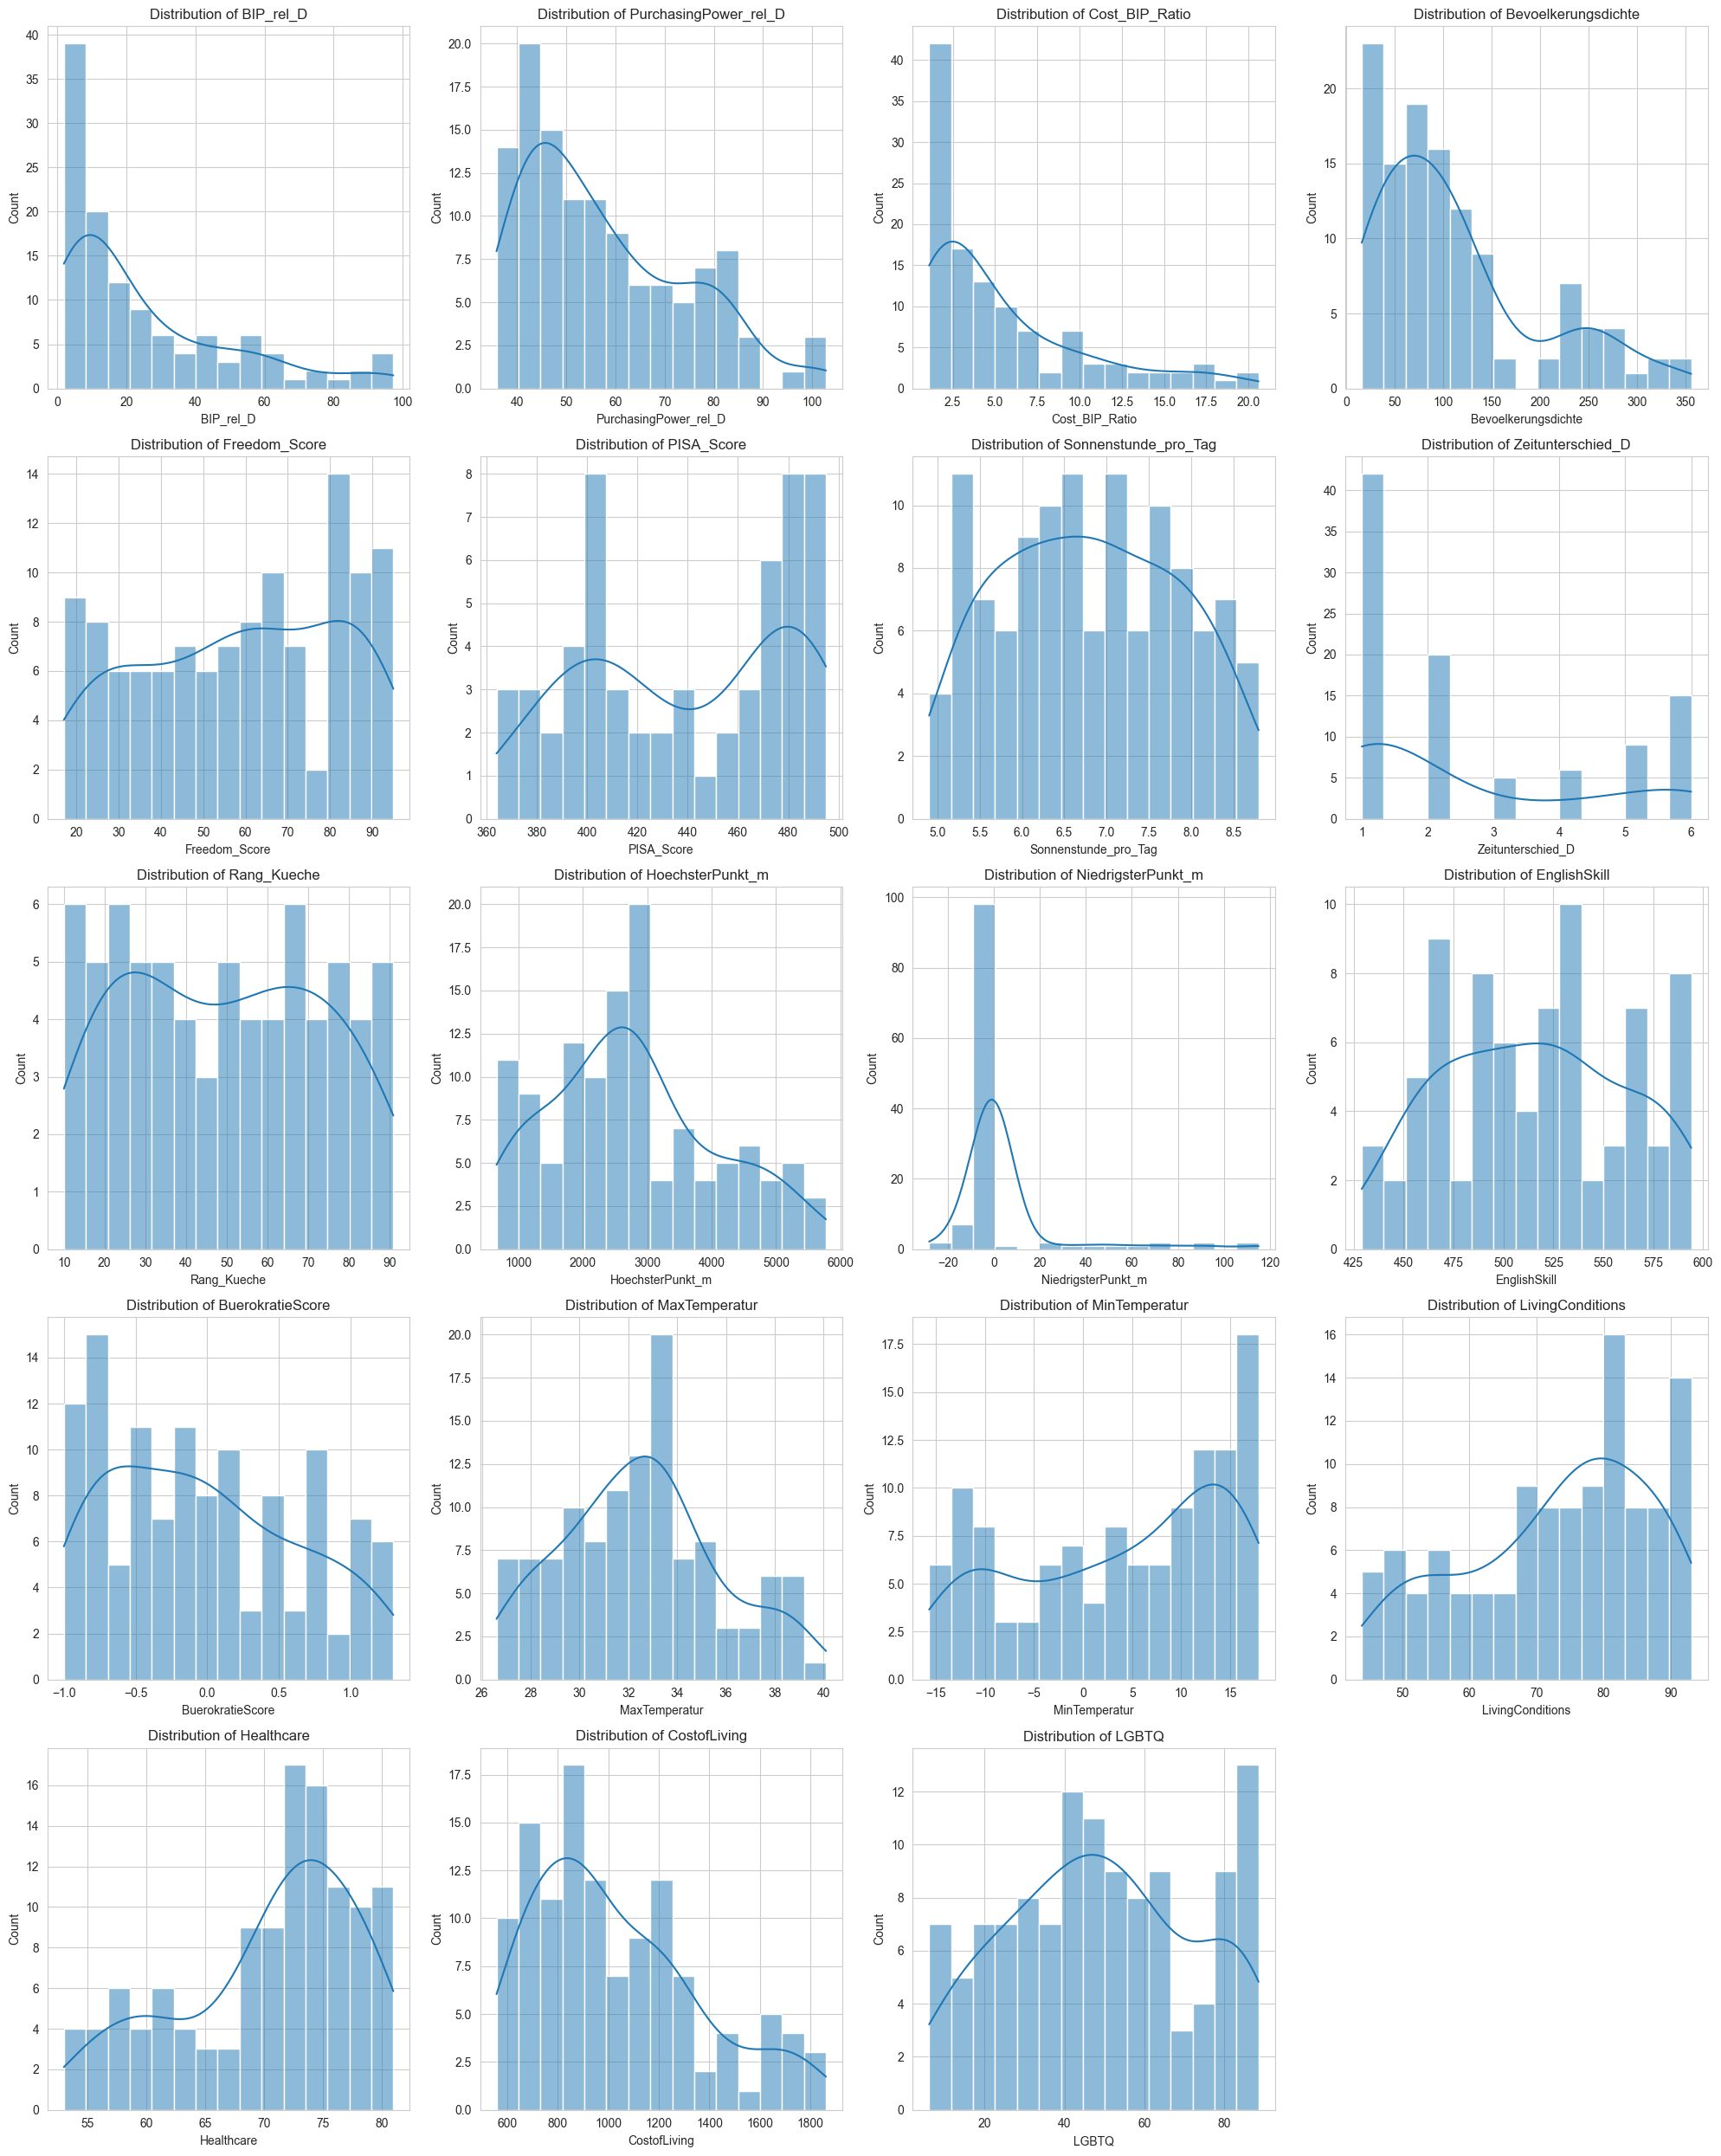

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set style
sns.set_style("whitegrid")

# Get numeric columns
numeric_cols = safe_countries_enough_data_red.select_dtypes(include=[np.number]).columns

# Create subplots
n_cols = 4
n_rows = len(numeric_cols) // n_cols + (1 if len(numeric_cols) % n_cols > 0 else 0)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
axes = axes.flatten() if n_rows > 1 else [axes] if n_cols == 1 else axes
edges_dict={}
for i, col in enumerate(numeric_cols):
    df_to_plot=skew_trimmer(col)[0]
    sns.histplot(data=df_to_plot, x=col, ax=axes[i], kde=1, bins=15)
    axes[i].set_title(f'Distribution of {col}')
    # Create histogram and capture the bin information
    data = df_to_plot[col].dropna()

# Create histogram and capture the bin information
    if col == "Zeitunterschied_D":
        counts, bin_edges, patches = plt.hist(data, bins=5)
    else:
        counts, bin_edges, patches = plt.hist(data, bins=15)
    if col in int_cols:
        bin_edges = bin_edges.round(0).astype(int)
    else:
        bin_edges = bin_edges.round(1)
    edges_dict[col]=bin_edges
    print(f"Bin edges: {bin_edges}")
    print(f"Bin counts: {counts}")
    print(f"Number of bins: {len(bin_edges) - 1}")



# Hide unused subplots
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

In [62]:
# First install the library if you haven't: pip install pycountry-convert
import pycountry_convert as pc

def get_continent_from_iso3(iso3_code):
    """
    Convert ISO-3 country code to continent name
    """
    try:
        # Convert ISO3 to ISO2
        iso2_code = pc.country_alpha3_to_country_alpha2(iso3_code)
        # Get continent code
        continent_code = pc.country_alpha2_to_continent_code(iso2_code)
        # Convert continent code to continent name
        continent_name = pc.convert_continent_code_to_continent_name(continent_code)
        return continent_name
    except:
        return "Unknown"

# Test with some examples
test_codes = ['USA', 'GBR', 'DEU', 'JPN', 'BRA', 'EGY', 'AUS']
for code in test_codes:
    continent = get_continent_from_iso3(code)
    print(f"{code}: {continent}")

USA: North America
GBR: Europe
DEU: Europe
JPN: Asia
BRA: South America
EGY: Africa
AUS: Oceania


In [63]:
english_to_german_continents = {
    'Europe': 'Europa',
    'North America': 'Nordamerika', 
    'South America': 'Südamerika',
    'Asia': 'Asien',
    'Africa': 'Afrika',
    'Oceania': 'Ozeanien',
    'Antarctica': 'Antarktis',
    'Unknown': 'Unbekannt'
}

In [64]:
country_info_json=[]
for isocode in countries_dict.keys():
    print(isocode)
    continent=get_continent_from_iso3(isocode)
    land=df_to_check[df_to_check["Country Code"]==isocode]["Land"].values[0]
    country_name=df_to_check[df_to_check["Country Code"]==isocode]["Country Name"].values[0]
    german_continent_name=english_to_german_continents[continent]
    country_entry={"id":isocode,"label":land,"country":country_name,"groupID":german_continent_name,"output":countries_dict[isocode]}
    country_info_json.append(country_entry)
country_info_json


ALB
DZA
AGO
ARG
ARM
AUS
AUT
AZE
BHR
BGD
BEL
BLZ
BEN
BOL
BIH
BWA
BRA
BGR
BFA
BDI
CPV
KHM
CMR
CAN
TCD
CHL
CHN
COL
COM
COD
COG
CRI
CIV
HRV
CUB
CYP
CZE
DNK
DJI
DOM
ECU
EGY
SLV
GNQ
ERI
EST
SWZ
ETH
FIN
FRA
GAB
GMB
GEO
DEU
GHA
GRC
GTM
GIN
GNB
GUY
HND
HUN
ISL
IND
IDN
IRQ
IRL
ISR
ITA
JAM
JPN
JOR
KAZ
KEN
KOR
KWT
KGZ
LAO
LVA
LBN
LSO
LBR
LTU
LUX
MDG
MWI
MYS
MLT
MRT
MUS
MEX
MDA
MNG
MNE
MAR
MOZ
NAM
NPL
NLD
NZL
NIC
NGA
MKD
NOR
OMN
PAK
PAN
PNG
PRY
PER
PHL
POL
PRT
QAT
ROU
RUS
RWA
STP
SAU
SEN
SRB
SYC
SLE
SGP
SVK
SVN
ZAF
ESP
LKA
SUR
SWE
CHE
TJK
TZA
THA
TGO
TTO
TUN
TUR
TKM
UGA
ARE
GBR
USA
URY
UZB
VEN
VNM
ZMB
ZWE


[{'id': 'ALB',
  'label': 'Albanien',
  'country': 'Albania',
  'groupID': 'Europa',
  'output': [{'id': 'BIP_rel_D', 'displayValue': 17.9, 'binValue': 17.9},
   {'id': 'PurchasingPower_rel_D', 'displayValue': 55.2, 'binValue': 55.2},
   {'id': 'Cost_BIP_Ratio', 'displayValue': 3.1, 'binValue': 3.1},
   {'id': 'Bevoelkerungsdichte', 'displayValue': 100.2, 'binValue': 100.2},
   {'id': 'Freedom_Score', 'displayValue': 68, 'binValue': 68},
   {'id': 'PISA_Score', 'displayValue': 367, 'binValue': 367},
   {'id': 'Sonnenstunde_pro_Tag', 'displayValue': 7.0, 'binValue': 7.0},
   {'id': 'Zeitunterschied_D', 'displayValue': 0, 'binValue': 0},
   {'id': 'Rang_Kueche', 'displayValue': 77, 'binValue': 77},
   {'id': 'HoechsterPunkt_m', 'displayValue': 2764, 'binValue': 2764},
   {'id': 'NiedrigsterPunkt_m', 'displayValue': 0, 'binValue': 0},
   {'id': 'EnglishSkill', 'displayValue': 533, 'binValue': 533},
   {'id': 'BuerokratieScore', 'displayValue': 0.3, 'binValue': 0.3},
   {'id': 'MaxTemperat

In [65]:
import json

# Write with nice formatting
with open('country_info_formatted_jan.json', 'w', encoding='utf-8') as f:
    json.dump(country_info_json, f, 
              indent=4,           # 4-space indentation
              ensure_ascii=False, # Keep unicode characters (like ä, ü, ö)
              sort_keys=1)     # Sort keys alphabetically

print("Formatted JSON file saved!")

Formatted JSON file saved!


In [66]:
safe_countries_enough_data_red.columns

Index(['Country Name', 'Country Code', 'Land', 'BIP_rel_D',
       'PurchasingPower_rel_D', 'Cost_BIP_Ratio', 'Bevoelkerungsdichte',
       'Freedom_Score', 'PISA_Score', 'Sonnenstunde_pro_Tag',
       'Zeitunterschied_D', 'Rang_Kueche', 'HoechsterPunkt_m',
       'NiedrigsterPunkt_m', 'EnglishSkill', 'BuerokratieScore',
       'MaxTemperatur', 'MinTemperatur', 'LivingConditions', 'Healthcare',
       'CostofLiving', 'LGBTQ', 'Mehrals5Morde_pro_100k_boolean',
       'Mehrals1000Deutsche_boolean', 'Alkoholverbot_boolean',
       'Kueste_boolean', 'Christian_boolean', 'Muslim_boolean',
       'Jewish_boolean'],
      dtype='object')

In [67]:
# Fixed version - use lists as VALUES, not wrapped in sets
classifier_dict = {
    "Geografie/Klima": [
        'Sonnenstunde_pro_Tag', 'Kueste_boolean', 'HoechsterPunkt_m', 
        'NiedrigsterPunkt_m', 'MaxTemperatur', 'MinTemperatur', 'Zeitunterschied_D'
    ],
    
    "Wirtschaftslage/Gesundheit": [
        'BIP_rel_D', 'PurchasingPower_rel_D', 'Cost_BIP_Ratio', 
        'CostofLiving', 'LivingConditions', 'Healthcare'
    ],
    
    "Freiheit/Sicherheit": [
        'Mehrals5Morde_pro_100k_boolean', 'Freedom_Score', 'BuerokratieScore', 'LGBTQ', 'Alkoholverbot_boolean'
    ],
    
    "Menschen/Religion": [
        'Bevoelkerungsdichte', 'PISA_Score', 'Rang_Kueche', 
        'EnglishSkill', 'Mehrals1000Deutsche_boolean','Christian_boolean', 'Muslim_boolean',
        'Jewish_boolean'
    ]
}

print(classifier_dict)

{'Geografie/Klima': ['Sonnenstunde_pro_Tag', 'Kueste_boolean', 'HoechsterPunkt_m', 'NiedrigsterPunkt_m', 'MaxTemperatur', 'MinTemperatur', 'Zeitunterschied_D'], 'Wirtschaftslage/Gesundheit': ['BIP_rel_D', 'PurchasingPower_rel_D', 'Cost_BIP_Ratio', 'CostofLiving', 'LivingConditions', 'Healthcare'], 'Freiheit/Sicherheit': ['Mehrals5Morde_pro_100k_boolean', 'Freedom_Score', 'BuerokratieScore', 'LGBTQ', 'Alkoholverbot_boolean'], 'Menschen/Religion': ['Bevoelkerungsdichte', 'PISA_Score', 'Rang_Kueche', 'EnglishSkill', 'Mehrals1000Deutsche_boolean', 'Christian_boolean', 'Muslim_boolean', 'Jewish_boolean']}


In [68]:
# Create a reverse mapping: column -> category
column_to_category = {}
for category, columns in classifier_dict.items():
    for column in columns:
        column_to_category[column] = category

print("Column to Category mapping:")
print(column_to_category)

Column to Category mapping:
{'Sonnenstunde_pro_Tag': 'Geografie/Klima', 'Kueste_boolean': 'Geografie/Klima', 'HoechsterPunkt_m': 'Geografie/Klima', 'NiedrigsterPunkt_m': 'Geografie/Klima', 'MaxTemperatur': 'Geografie/Klima', 'MinTemperatur': 'Geografie/Klima', 'Zeitunterschied_D': 'Geografie/Klima', 'BIP_rel_D': 'Wirtschaftslage/Gesundheit', 'PurchasingPower_rel_D': 'Wirtschaftslage/Gesundheit', 'Cost_BIP_Ratio': 'Wirtschaftslage/Gesundheit', 'CostofLiving': 'Wirtschaftslage/Gesundheit', 'LivingConditions': 'Wirtschaftslage/Gesundheit', 'Healthcare': 'Wirtschaftslage/Gesundheit', 'Mehrals5Morde_pro_100k_boolean': 'Freiheit/Sicherheit', 'Freedom_Score': 'Freiheit/Sicherheit', 'BuerokratieScore': 'Freiheit/Sicherheit', 'LGBTQ': 'Freiheit/Sicherheit', 'Alkoholverbot_boolean': 'Freiheit/Sicherheit', 'Bevoelkerungsdichte': 'Menschen/Religion', 'PISA_Score': 'Menschen/Religion', 'Rang_Kueche': 'Menschen/Religion', 'EnglishSkill': 'Menschen/Religion', 'Mehrals1000Deutsche_boolean': 'Menschen/

In [69]:
id_title={'Sonnenstunde_pro_Tag': 'Durchschnittliche Sonnenstunden pro Tag',
  'Kueste_boolean': 'Zugang zum Meer', 
  'HoechsterPunkt_m': 'Höchster Punkt des Landes', 
  'NiedrigsterPunkt_m': "Niedrigster Punkt des Landes", 
  'MaxTemperatur': 'Maximale mittlere Monatstemperatur', 
  'MinTemperatur': 'Minimale mittlere Monatstemperatur', 
  'Zeitunterschied_D': 'Zeitverschiebung zu Deutschland', 
  'BIP_rel_D': 'Bruttoinlandsprodukt im Vergleich zu Deutschland', 
  'PurchasingPower_rel_D': 'Kaufkraft im Vergleich zu Deutschland', 
  'Cost_BIP_Ratio': 'Verhältnis Kaufkraft zu Bruttoinlandsprodukt', 
  'CostofLiving': 'Lebenshaltungskosten im Land', 
  'LivingConditions': 'Lebensqualität im Land', 
  'Healthcare': 'Qualität des Gesundheitssystems', 
  'Christian_boolean': 'Christliche Bevölkerung', 
  'Muslim_boolean': 'Muslimische Bevölkerung', 
  'Jewish_boolean': 'Jüdische Bevölkerung', 
  'Mehrals5Morde_pro_100k_boolean': 'Hohes Maß an Gewaltkriminalität', 
  'Freedom_Score': 'Freiheit-Score gemäß Freedom House', 
  'BuerokratieScore': 'Bürokratie-Score der Weltbank', 
  'LGBTQ': 'LGBTQ-Rechte-Index gemäß EqualDex ', 
  'Alkoholverbot_boolean': 'Striktes Alkoholverbot', 
  'Bevoelkerungsdichte': 'Bevölkerungsdichte', 
  'PISA_Score': 'PISA-Durchschnitt 2022', 
  'Rang_Kueche': 'Ranking der Küche gemäß Taste Atlas', 
  'EnglishSkill': 'Englisch-Skills gemäß EF', 
  'Mehrals1000Deutsche_boolean': 'Deutsche Community im Land'}


In [70]:
id_einheit={'Sonnenstunde_pro_Tag': 'h/Tag',
            'Kueste_boolean': 'Nein/Ja',
  'HoechsterPunkt_m': 'm', 
  'NiedrigsterPunkt_m': 'm', 
  'MaxTemperatur': '°C', 
  'MinTemperatur': '°C', 
  'Zeitunterschied_D': 'h', 
  'BIP_rel_D': '%', 
  'PurchasingPower_rel_D': '%', 
  'Cost_BIP_Ratio': 'Ratio', 
  'CostofLiving': '$', 
  'LivingConditions': 'Indexpunkte', 
  'Healthcare': 'Indexpunkte', 
  'Freedom_Score': 'Indexpunkte', 
  'BuerokratieScore': 'Indexpunkte', 
  'LGBTQ': 'Indexpunkte', 
  'Alkoholverbot': 'Nein/Ja', 
  'Bevoelkerungsdichte': 'Ew./km2', 
  'PISA_Score': 'Indexpunkte', 
  'Rang_Kueche': 'Rang', 
  'EnglishSkill': 'Indexpunkte', 
  'Anzahl_der_Deutschen_numeric': 'Ew.',
  'Christian_boolean': 'Nein/Ja', 
  'Muslim_boolean': 'Nein/Ja', 
  'Jewish_boolean': 'Nein/Ja', 
  'Mehrals5Morde_pro_100k_boolean': 'Nein/Ja', 
    'Alkoholverbot_boolean': 'Nein/Ja', 
    "Mehrals1000Deutsche_boolean": 'Nein/Ja'}

In [71]:
id_descript={'Sonnenstunde_pro_Tag': 'Wie viel Sonnenstunden pro Tag sollte es mindestens geben und wie viele sind zu viel?',
            'Kueste_boolean': 'Wollen Sie, dass Ihr Wunschland eine Meeresküste hat?',
  'HoechsterPunkt_m': 'Wie hoch soll der höchste Punkt des Landes mindestens sein und kann es ein oberes Limit geben?', 
  'NiedrigsterPunkt_m': 'Wie niedrig oder hoch soll der niedrigste Punkt des Landes liegen?', 
  'MaxTemperatur': 'Wie warm darf es auf Monatsbasis im Mittel maximal werden in Ihrem Wunschland?', 
  'MinTemperatur': 'Wie kalt darf es auf Monatsbasis im Mittel minimal werden in Ihrem Wunschland?', 
  'Zeitunterschied_D': 'In welchem Rahmen sollte sich der Zeitunterschied zu Deutschland befinden?', 
  'BIP_rel_D': 'Wie groß sollte die Wirtschaftsleistung pro Kopf im Vergleich zu Deutschland sein?', 
  'PurchasingPower_rel_D': 'In welchem Bereich sollte sich die Kaufkraft befinden im Vergleich zu Deutschland?', 
  'Cost_BIP_Ratio': 'Wo sollte sich das Verhältnis der Kaufkraft zur Wirtschaftsleistung befinden?', 
  'CostofLiving': 'In welchem Bereich sollten sich die Lebenshaltungskosten in US-Dollar befinden?', 
  'LivingConditions': 'In welchem Bereich sollte sich die Lebensqualität befinden? (Index von 0 bis 100 gemäß Legatum Institut)', 
  'Healthcare': 'In welchem Bereich sollte sich die Gesundheitsversorgung befinden? (Index von 0 bis 100 gemäß Legatum Institut)', 
  'Freedom_Score': 'Wo sollte das Niveau der bürgerlichen Freiheiten liegen? (Index von 0 bis 100 gemäß Freedom House Institut)', 
  'BuerokratieScore': 'Wo sollte das Maß an Ordnung und Bürokratie liegen? (Index von -5 bis 5 in Indexpunkten der OECD)', 
  'LGBTQ': 'Wie sollte es um die LGBTQ-Rechte im Land stehen? (Index von 0 bis 100 gemäß EqualDex Institut)', 
  'Alkoholverbot': 'Herrscht ein striktes Alkoholverbot im Land?',  
  'Bevoelkerungsdichte': 'Wie dicht soll oder darf das Land besiedelt sein? (Einwohner pro Quadratkilometer)', 
  'PISA_Score': 'Welches Bildungsniveau ist für Sie wünschenswert im Land? (Durchschnitt der PISA-Ergebnisse 2022)', 
  'Rang_Kueche': 'Wie gut soll die Küche des Landes sein? (Ranking gemäß Taste Atlas)', 
  'EnglishSkill': 'Wie gut sollten die Englischkenntnisse in der Bevölkerung sein? (Punktzahl gemäß Education First)',
  'Christian_boolean': 'Gibt es einen nennenswerten christlichen Bevölkerungsanteil? (mehr als ein Prozent)', 
  'Muslim_boolean': 'Gibt es einen nennenswerten muslimischen Bevölkerungsanteil? (mehr als ein Prozent)', 
  'Jewish_boolean': 'Gibt es einen nennenswerten jüdischen Bevölkerungsanteil? (mehr als ein Prozent)', 
  'Mehrals5Morde_pro_100k_boolean': 'Gibt es viele Gewaltverbrechen? (mehr als 5 Morde pro 100.000 Einwohner)', 
    'Alkoholverbot_boolean': 'Herrscht ein striktes Alkoholverbot im Land?', 
    "Mehrals1000Deutsche_boolean": 'Gibt es eine nennenswerte deutsche Expat-Community? (mehr als 1000 Deutsche im Land)'}

In [72]:
boundaries_dict

{'BIP_rel_D': {'upper': 97.6, 'lower': 1.8},
 'PurchasingPower_rel_D': {'upper': 103.2, 'lower': 35.7},
 'Cost_BIP_Ratio': {'upper': 20.7, 'lower': 1.0},
 'Bevoelkerungsdichte': {'upper': 359.1, 'lower': 15.7},
 'Freedom_Score': {'upper': 96, 'lower': 15},
 'PISA_Score': {'upper': 496, 'lower': 361},
 'Sonnenstunde_pro_Tag': {'upper': 8.9, 'lower': 4.8},
 'Zeitunterschied_D': {'upper': 7, 'lower': 0},
 'Rang_Kueche': {'upper': 91, 'lower': 9},
 'HoechsterPunkt_m': {'upper': 5787, 'lower': 656},
 'NiedrigsterPunkt_m': {'upper': 116, 'lower': -28},
 'EnglishSkill': {'upper': 594, 'lower': 428},
 'BuerokratieScore': {'upper': 1.4, 'lower': -1.1},
 'MaxTemperatur': {'upper': 40.3, 'lower': 26.5},
 'MinTemperatur': {'upper': 18.0, 'lower': -15.9},
 'LivingConditions': {'upper': 94, 'lower': 43},
 'Healthcare': {'upper': 82, 'lower': 52},
 'CostofLiving': {'upper': 1873, 'lower': 556},
 'LGBTQ': {'upper': 88.7, 'lower': 5.6},
 'Mehrals5Morde_pro_100k_boolean': {},
 'Mehrals1000Deutsche_boole

In [73]:
colour_category_dict={
    "Geografie/Klima": "yellow",
    "Wirtschaftslage/Gesundheit": "green",  
    "Freiheit/Sicherheit": "blue",  
    "Menschen/Religion": "orange"}

In [74]:
input_json=[]
for category in classifier_dict.keys():
    print(category)
    print(classifier_dict[category])
    items_json=[]
    for item in classifier_dict[category]:
        #print(item)
        #print(category)
        if "_boolean" in item:
            filtertype="boolean"
            category_input={
            "type": filtertype,
            "id": item,
            "title": id_title[item],
            "description": id_descript[item],
            "color": colour_category_dict[category]
           
            }
        else:
            filtertype="slider"
            category_input={
            "type": filtertype,
            "id": item,
            "title": id_title[item],
            "description": id_descript[item],

            "color": colour_category_dict[category],
            "filter": {
            "min":boundaries_dict[item]["lower"],
            "max": boundaries_dict[item]["upper"],

            "threshold": edges_dict[item].tolist(),
            "unit": id_einheit[item]
            }
  
    }
        items_json.append(category_input)
    input_json.append({
        "title": category,
        "color": colour_category_dict[category],
        "items": items_json
    })
input_json
        

Geografie/Klima
['Sonnenstunde_pro_Tag', 'Kueste_boolean', 'HoechsterPunkt_m', 'NiedrigsterPunkt_m', 'MaxTemperatur', 'MinTemperatur', 'Zeitunterschied_D']
Wirtschaftslage/Gesundheit
['BIP_rel_D', 'PurchasingPower_rel_D', 'Cost_BIP_Ratio', 'CostofLiving', 'LivingConditions', 'Healthcare']
Freiheit/Sicherheit
['Mehrals5Morde_pro_100k_boolean', 'Freedom_Score', 'BuerokratieScore', 'LGBTQ', 'Alkoholverbot_boolean']
Menschen/Religion
['Bevoelkerungsdichte', 'PISA_Score', 'Rang_Kueche', 'EnglishSkill', 'Mehrals1000Deutsche_boolean', 'Christian_boolean', 'Muslim_boolean', 'Jewish_boolean']


[{'title': 'Geografie/Klima',
  'color': 'yellow',
  'items': [{'type': 'slider',
    'id': 'Sonnenstunde_pro_Tag',
    'title': 'Durchschnittliche Sonnenstunden pro Tag',
    'description': 'Wie viel Sonnenstunden pro Tag sollte es mindestens geben und wie viele sind zu viel?',
    'color': 'yellow',
    'filter': {'min': 4.8,
     'max': 8.9,
     'threshold': [4.9,
      5.2,
      5.4,
      5.7,
      5.9,
      6.2,
      6.5,
      6.7,
      7.0,
      7.2,
      7.5,
      7.8,
      8.0,
      8.3,
      8.5,
      8.8],
     'unit': 'h/Tag'}},
   {'type': 'boolean',
    'id': 'Kueste_boolean',
    'title': 'Zugang zum Meer',
    'description': 'Wollen Sie, dass Ihr Wunschland eine Meeresküste hat?',
    'color': 'yellow'},
   {'type': 'slider',
    'id': 'HoechsterPunkt_m',
    'title': 'Höchster Punkt des Landes',
    'description': 'Wie hoch soll der höchste Punkt des Landes mindestens sein und kann es ein oberes Limit geben?',
    'color': 'yellow',
    'filter': {'min': 

In [75]:
input_json

[{'title': 'Geografie/Klima',
  'color': 'yellow',
  'items': [{'type': 'slider',
    'id': 'Sonnenstunde_pro_Tag',
    'title': 'Durchschnittliche Sonnenstunden pro Tag',
    'description': 'Wie viel Sonnenstunden pro Tag sollte es mindestens geben und wie viele sind zu viel?',
    'color': 'yellow',
    'filter': {'min': 4.8,
     'max': 8.9,
     'threshold': [4.9,
      5.2,
      5.4,
      5.7,
      5.9,
      6.2,
      6.5,
      6.7,
      7.0,
      7.2,
      7.5,
      7.8,
      8.0,
      8.3,
      8.5,
      8.8],
     'unit': 'h/Tag'}},
   {'type': 'boolean',
    'id': 'Kueste_boolean',
    'title': 'Zugang zum Meer',
    'description': 'Wollen Sie, dass Ihr Wunschland eine Meeresküste hat?',
    'color': 'yellow'},
   {'type': 'slider',
    'id': 'HoechsterPunkt_m',
    'title': 'Höchster Punkt des Landes',
    'description': 'Wie hoch soll der höchste Punkt des Landes mindestens sein und kann es ein oberes Limit geben?',
    'color': 'yellow',
    'filter': {'min': 

In [76]:

# Write with nice formatting
with open('input_formatted_jan.json', 'w', encoding='utf-8') as f:
    json.dump(input_json, f, 
              indent=4,           # 4-space indentation
              ensure_ascii=False, # Keep unicode characters (like ä, ü, ö)
              sort_keys=1)     # Sort keys alphabetically

print("Formatted JSON file saved!")

Formatted JSON file saved!


In [77]:
bin_edges

array([ 6.1, 11.6, 17.1, 22.6, 28.1, 33.6, 39.1, 44.6, 50.1, 55.6, 61.1,
       66.6, 72.1, 77.6, 83.1, 88.6])